# Model 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Model parameters (illustrative values)
alpha = 0.8       # Plant growth rate
a = 0.1           # Caterpillar consumption rate
mu = 0.2          # Caterpillar death rate
epsilon = 0.5     # Conversion efficiency
K = 10            # Plant carrying capacity


# Model 1 differential equations
def model1(t, y, alpha, a, mu, epsilon, K):
    p, c = y

    dp = alpha * p * (1 - p/K) - a * p * c
    dc = -mu * c + epsilon * a * p * c

    return [dp, dc]

In [ ]:
def equilibria(alpha, a, mu, epsilon, K):

    # Equilibrium 1: Both populations extinct
    E1 = (0, 0)

    # Equilibrium 2: Plants survive, caterpillars extinct
    E2 = (K, 0)

    # Equilibrium 3: Coexistence
    K_critical = mu / (epsilon * a)

    if K > K_critical:
        p_star = K_critical
        c_star = (alpha / a) * (1 - K_critical / K)
        E3 = (p_star, c_star)
    else:
        E3 = None

    return E1, E2, E3

#### Found equlibiria:

In [ ]:
E1, E2, E3 = equilibria(alpha, a, mu, epsilon, K)

print("Equilibrium 1:", E1)
print("Equilibrium 2:", E2)
print("Equilibrium 3:", E3)

Equilibrium 1: (0, 0)
Equilibrium 2: (10, 0)
Equilibrium 3: (4.0, 4.8)


## Calculate Stability


In [ ]:
def jacobian(p, c, alpha, a, mu, epsilon, K):

    return np.array([
        [alpha * (1 - 2*p/K) - a*c, -a*p],
        [epsilon * a*c, -mu + epsilon*a*p]
    ])


def stability(p, c, alpha, a, mu, epsilon, K):

    J = jacobian(p, c, alpha, a, mu, epsilon, K)
    eigenvalues = np.linalg.eigvals(J)

    if np.any(np.real(eigenvalues) > 1e-8) and np.any(np.real(eigenvalues) < -1e-8):
        return "Saddle", eigenvalues

    elif np.all(np.real(eigenvalues) < -1e-8):
        return "Stable", eigenvalues

    elif np.all(np.real(eigenvalues) > 1e-8):
        return "Unstable", eigenvalues

    else:
        return "Nonhyperbolic", eigenvalues

##### evaluate equilibria:

In [ ]:
equilibrium_list = [
    ("E1", E1),
    ("E2", E2),
    ("E3", E3)
]

for name, E in equilibrium_list:

    if E is not None:
        result, eigenvalues = stability(
            E[0], E[1], alpha, a, mu, epsilon, K
        )

        print(f"{name}: {E}")
        print(f"Stability: {result}")
        print(f"Eigenvalues: {eigenvalues}\n")

E1: (0, 0)
Stability: Saddle
Eigenvalues: [ 0.8+0.j -0.2+0.j]

E2: (10, 0)
Stability: Saddle
Eigenvalues: [-0.8+0.j  0.3+0.j]

E3: (4.0, 4.8)
Stability: Stable
Eigenvalues: [-0.16+0.26532998j -0.16-0.26532998j]



## Bifurcation Plot

4.0


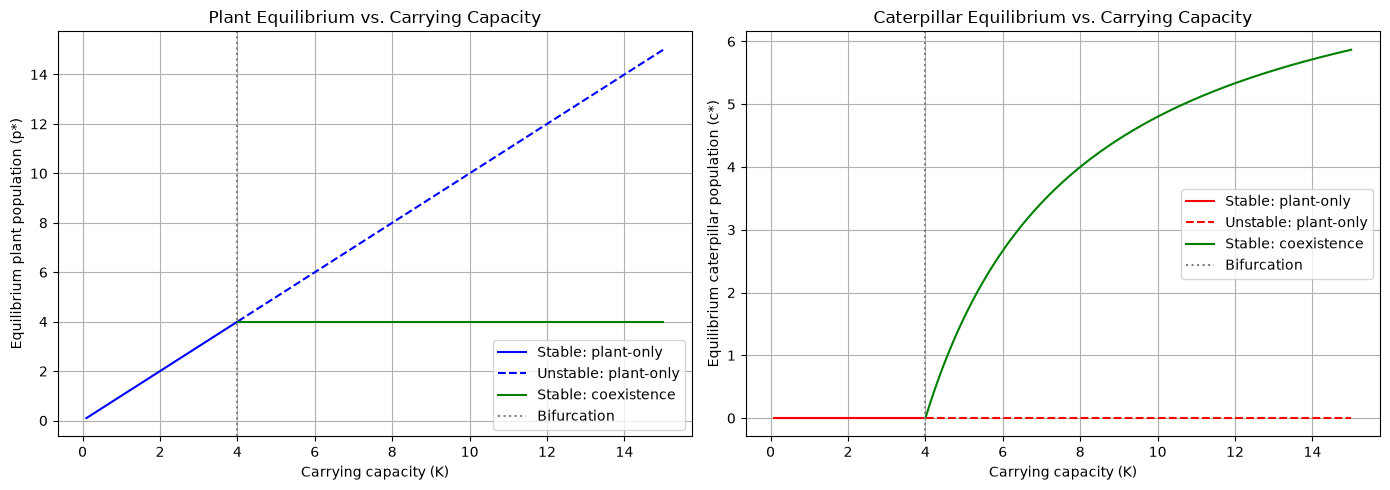

In [ ]:
# From what I understand, a bifurcation happens when changing a parameter in a differential equation causes a qualitative change in the system's behavior.
# So I'm going to focus on what happens if we change K, the carrying capacity
# For example, Imagine the environment can only support 100 plants. There might not be enough plants to sustain a caterpillar population. Caterpillars eventually die out.
# But if the environment can support 10,000 plants, there are potentially enough plants to support both populations. Caterpillars can survive, and both populations can coexist.

# Range of carrying capacities
K_values = np.linspace(0.1, 15, 500)

# Critical carrying capacity
K_critical = mu / (epsilon * a) # I got this by using the coexistence equilibrium and solving for the minimum carrying capacity for the coexistence equilibrium

# Calculate equilibrium branches
p_plant = K_values
c_plant = np.zeros_like(K_values)

p_coexist = np.full_like(K_values, np.nan)
c_coexist = np.full_like(K_values, np.nan)

coexist_mask = K_values > K_critical

p_coexist[coexist_mask] = K_critical

c_coexist[coexist_mask] = (
    alpha / a * (1 - K_critical / K_values[coexist_mask])
)


# Create bifurcation diagrams
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Split branches into stable and unstable portions
stable_mask = K_values < K_critical
unstable_mask = K_values > K_critical

# Plot plant equilibrium
axes[0].plot(
    K_values[stable_mask],
    p_plant[stable_mask],
    'b-', label='Stable: plant-only'
)

axes[0].plot(
    K_values[unstable_mask],
    p_plant[unstable_mask],
    'b--', label='Unstable: plant-only'
)

axes[0].plot(
    K_values[coexist_mask],
    p_coexist[coexist_mask],
    'g-', label='Stable: coexistence'
)

axes[0].axvline(
    K_critical, color='gray', linestyle=':', label='Bifurcation'
)

axes[0].set_xlabel('Carrying capacity (K)')
axes[0].set_ylabel('Equilibrium plant population (p*)')
axes[0].set_title('Plant Equilibrium vs. Carrying Capacity')
axes[0].legend()
axes[0].grid()


# Plot caterpillar equilibrium
axes[1].plot(
    K_values[stable_mask],
    c_plant[stable_mask],
    'r-', label='Stable: plant-only'
)

axes[1].plot(
    K_values[unstable_mask],
    c_plant[unstable_mask],
    'r--', label='Unstable: plant-only'
)

axes[1].plot(
    K_values[coexist_mask],
    c_coexist[coexist_mask],
    'g-', label='Stable: coexistence'
)

axes[1].axvline(
    K_critical, color='gray', linestyle=':', label='Bifurcation'
)

axes[1].set_xlabel('Carrying capacity (K)')
axes[1].set_ylabel('Equilibrium caterpillar population (c*)')
axes[1].set_title('Caterpillar Equilibrium vs. Carrying Capacity')
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

### Simulate the populations over time

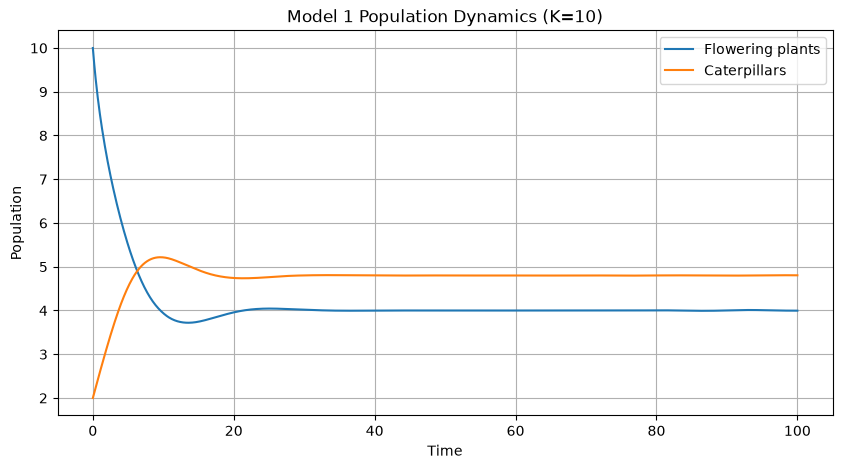

In [ ]:
# Initial populations
initial_conditions = [10, 2]

# Time interval
t_span = (0, 100)
t_eval = np.linspace(*t_span, 1000)

# Solve the system
solution = solve_ivp(
    model1,
    t_span,
    initial_conditions,
    t_eval=t_eval,
    args=(alpha, a, mu, epsilon, K)
)

# Plot populations over time
plt.figure(figsize=(10, 5))

plt.plot(solution.t, solution.y[0], label='Flowering plants')
plt.plot(solution.t, solution.y[1], label='Caterpillars')

plt.xlabel('Time')
plt.ylabel('Population')
plt.title(f'Model 1 Population Dynamics (K={K})')
plt.legend()
plt.grid()
plt.show()


## Limitations of Model 1

Model 1 considers the interactions between flowering plants and caterpillars, but it does not account for the role of bees in the ecosystem. This is a significant limitation because bees pollinate flowering plants, contributing to their reproduction and population growth. Without including bees, the model assumes that plant growth is independent of pollination and cannot capture how changes in bee populations might affect plant populations.

Additionally, bees may indirectly influence caterpillar populations. If increased pollination leads to greater plant growth, more food may become available for caterpillars, potentially allowing their population to increase as well. Conversely, declining bee populations could reduce plant reproduction and limit the resources available to caterpillars.

Therefore, Model 1 is insufficient to fully describe the ecosystem because it overlooks the mutualistic relationship between bees and flowering plants. Adding bees to Model 2 will allow us to investigate how pollination influences plant growth, how bees affect the balance between plants and caterpillars, and whether pollination can help offset the effects of herbivory.